# Spaceship Titanic

## Dataset Description

In this competition your task is to predict whether a passenger was transported to an alternate dimension during the Spaceship Titanic's collision with the spacetime anomaly. To help you make these predictions, you're given a set of personal records recovered from the ship's damaged computer system.

https://www.kaggle.com/competitions/spaceship-titanic/data

## Data Field Descriptions

- `PassengerId` - A unique Id for each passenger. Each Id takes the form `gggg_pp` where `gggg` indicates a group the passenger is travelling with and `pp` is their number within the group. People in a group are often family members, but not always.
- `HomePlanet` - The planet the passenger departed from, typically their planet of permanent residence.
- `CryoSleep` - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
- `Cabin` - The cabin number where the passenger is staying. Takes the form `deck/num/side`, where side can be either `P` for Port or `S` for Starboard.
- `Destination` - The planet the passenger will be debarking to.
- `Age` - The age of the passenger.
- `VIP` - Whether the passenger has paid for special VIP service during the voyage.
- `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
- `Name` - The first and last names of the passenger.
- `Transported` - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.

## Data Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("data/train.csv")

In [3]:
df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False


In [4]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [5]:
df[["PassengerId", "HomePlanet", "CryoSleep", "Cabin", "Destination", "VIP", "Name", "Transported"]].describe()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name,Transported
count,8693,8492,8476,8494,8511,8490,8493,8693
unique,8693,3,2,6560,3,2,8473,2
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Elaney Webstephrey,True
freq,1,4602,5439,8,5915,8291,2,4378


Let's investigate why the data contains several people with the same name.

In [6]:
df[df['Name'].duplicated(keep=False)].dropna(subset="Name").sort_values(["Name"])

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7270,7775_01,Europa,False,C/253/P,55 Cancri e,28.0,False,7.0,489.0,0.0,4.0,6027.0,Alraium Disivering,False
6296,6665_01,Europa,True,B/222/P,55 Cancri e,17.0,False,0.0,0.0,0.0,0.0,0.0,Alraium Disivering,True
476,0512_02,Europa,True,D/18/S,TRAPPIST-1e,55.0,False,0.0,0.0,0.0,0.0,0.0,Ankalik Nateansive,True
2930,3176_01,Europa,False,E/196/P,TRAPPIST-1e,77.0,False,0.0,9032.0,0.0,128.0,1464.0,Ankalik Nateansive,True
8488,9071_01,Earth,False,F/1855/P,55 Cancri e,22.0,False,0.0,0.0,1072.0,46.0,3.0,Anton Woody,False
2991,3236_03,Earth,False,E/200/P,TRAPPIST-1e,18.0,False,0.0,30.0,0.0,756.0,5.0,Anton Woody,False
2559,2746_01,Mars,False,F/569/P,TRAPPIST-1e,52.0,False,758.0,0.0,356.0,5.0,0.0,Apix Wala,False
4108,4387_01,Mars,False,F/902/P,PSO J318.5-22,32.0,False,192.0,0.0,441.0,18.0,0.0,Apix Wala,False
7871,8398_01,Europa,True,B/329/S,TRAPPIST-1e,15.0,False,0.0,0.0,0.0,0.0,0.0,Asch Stradick,True
6086,6432_01,Europa,False,D/202/P,55 Cancri e,55.0,False,114.0,222.0,0.0,2575.0,2919.0,Asch Stradick,False


We have a few duplicate names, but they all seem to be different people, so I'm gonna keep them.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [8]:
df.loc[df.duplicated()]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported


In [9]:
df.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

## Split Train Dataset into Train and Validation

In [10]:
#train_val_split = int(df.shape[0] * 0.8)

#train_df = df.iloc[:train_val_split, :].reset_index(drop=True).copy()
#val_df = df.iloc[train_val_split:, :].reset_index(drop=True).copy()

In [11]:
#train_df.shape, val_df.shape

## Data Preparation

### Feature Creation

In [12]:
cabin_splitted = df["Cabin"].str.split("/", expand=True)
df["Cabin_Deck"] = cabin_splitted[0]
df["Cabin_Num"] = cabin_splitted[1]
df["Cabin_Side"] = cabin_splitted[2]
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Cabin_Deck,Cabin_Num,Cabin_Side
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S


In [13]:
df["Cabin_Group_Size"] = df["Cabin"].map(df["Cabin"].value_counts())
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,1.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S,1.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,2.0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S,2.0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S,1.0


### Dropping Irrelevant Columns

In [14]:
df = df.drop(["PassengerId", "Cabin", "Name"], axis=1)
df.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,0,P,1.0
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,0,S,1.0
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A,0,S,2.0
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,0,S,2.0
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,1,S,1.0


### Renaming Columns and Changing Data Types

In [15]:
df = df.rename(columns={
    "HomePlanet": "Home_Planet",
    "CryoSleep": "Cryo_Sleep",
    "RoomService": "Room_Service",
    "FoodCourt": "Food_Court",
    "ShoppingMall": "Shopping_Mall",
    "VRDeck": "VR_Deck",
})

In [16]:
df = df[["Home_Planet", "Destination", "Age", "Cryo_Sleep", "VIP", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Deck", "Cabin_Num", "Cabin_Side", "Cabin_Group_Size", "Transported"]]

In [17]:
df.head()

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Deck,Cabin_Num,Cabin_Side,Cabin_Group_Size,Transported
0,Europa,TRAPPIST-1e,39.0,False,False,0.0,0.0,0.0,0.0,0.0,B,0,P,1.0,False
1,Earth,TRAPPIST-1e,24.0,False,False,109.0,9.0,25.0,549.0,44.0,F,0,S,1.0,True
2,Europa,TRAPPIST-1e,58.0,False,True,43.0,3576.0,0.0,6715.0,49.0,A,0,S,2.0,False
3,Europa,TRAPPIST-1e,33.0,False,False,0.0,1283.0,371.0,3329.0,193.0,A,0,S,2.0,False
4,Earth,TRAPPIST-1e,16.0,False,False,303.0,70.0,151.0,565.0,2.0,F,1,S,1.0,True


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Home_Planet       8492 non-null   str    
 1   Destination       8511 non-null   str    
 2   Age               8514 non-null   float64
 3   Cryo_Sleep        8476 non-null   object 
 4   VIP               8490 non-null   object 
 5   Room_Service      8512 non-null   float64
 6   Food_Court        8510 non-null   float64
 7   Shopping_Mall     8485 non-null   float64
 8   Spa               8510 non-null   float64
 9   VR_Deck           8505 non-null   float64
 10  Cabin_Deck        8494 non-null   str    
 11  Cabin_Num         8494 non-null   str    
 12  Cabin_Side        8494 non-null   str    
 13  Cabin_Group_Size  8494 non-null   float64
 14  Transported       8693 non-null   bool   
dtypes: bool(1), float64(7), object(2), str(5)
memory usage: 959.4+ KB


In [19]:
df["Home_Planet"] = df["Home_Planet"].astype("category")
df["Destination"] = df["Destination"].astype("category")
df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("bool")
df["VIP"] = df["VIP"].astype("bool")
df["Cabin_Deck"] = df["Cabin_Deck"].astype("category")
df["Cabin_Num"] = df["Cabin_Num"].astype("float")
df["Cabin_Side"] = df["Cabin_Side"].astype("category")
df["Cabin_Group_Size"] = df["Cabin_Group_Size"].astype("category")

In [20]:
df[["Home_Planet", "Destination", "Cryo_Sleep", "VIP", "Cabin_Deck", "Cabin_Side", "Cabin_Group_Size"]].describe()

,Home_Planet,Destination,Cryo_Sleep,VIP,Cabin_Deck,Cabin_Side,Cabin_Group_Size
count,8492,8511,8693,8693,8494,8494,8494.0
unique,3,3,2,2,8,2,8.0
top,Earth,TRAPPIST-1e,False,False,F,S,1.0
freq,4602,5915,5439,8291,2794,4288,5427.0


In [21]:
df.isna().sum()

Home_Planet         201
Destination         182
Age                 179
Cryo_Sleep            0
VIP                   0
Room_Service        181
Food_Court          183
Shopping_Mall       208
Spa                 183
VR_Deck             188
Cabin_Deck          199
Cabin_Num           199
Cabin_Side          199
Cabin_Group_Size    199
Transported           0
dtype: int64

## Feature Understanding

### Univariate and Bivariate Analysis

#### Home Planet

In [22]:
df["Home_Planet"].value_counts(dropna=False)

Home_Planet
Earth     4602
Europa    2131
Mars      1759
NaN        201
Name: count, dtype: int64

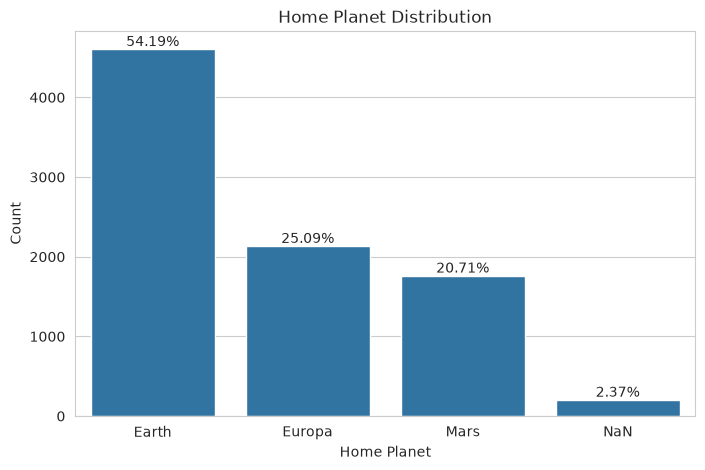

In [23]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Home_Planet"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Home_Planet"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Home Planet Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Home Planet")
plt.show()

##### Does Home Planet Affect Transported Status?

In [24]:
home_planet_crosstab = pd.crosstab(index=df["Transported"], columns=df["Home_Planet"], margins=True)
home_planet_crosstab = home_planet_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
home_planet_crosstab

,Earth,Europa,Mars,Total Cols
Not Transported,2651,727,839,4217
Transported,1951,1404,920,4275
Total Rows,4602,2131,1759,8492


In [103]:
home_planet_prob = home_planet_crosstab / home_planet_crosstab.loc["Total Rows"]
home_planet_prob

,Earth,Europa,Mars,Total Cols
Not Transported,0.576054,0.341154,0.476976,0.496585
Transported,0.423946,0.658846,0.523024,0.503415
Total Rows,1.000000,1.000000,1.000000,1.000000


In [105]:
home_planet_prob = home_planet_prob.stack()["Transported"].drop("Total Cols")

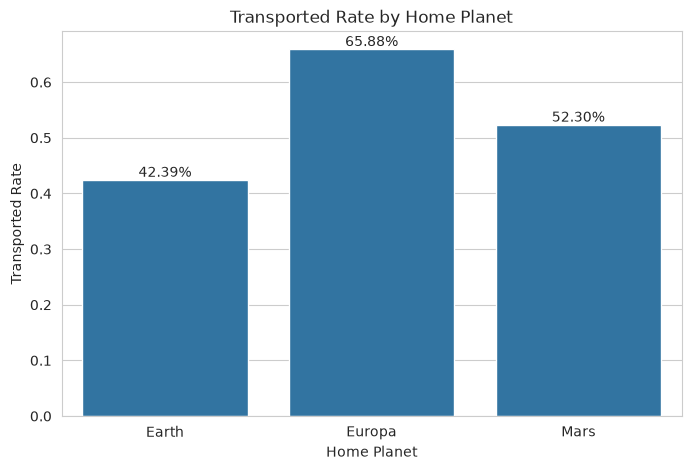

In [106]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(home_planet_prob)
ax.bar_label(ax.containers[0], labels=home_planet_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Home Planet")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Home Planet")
plt.show()

#### Destination

In [26]:
df["Destination"].value_counts(dropna=False)

Destination
TRAPPIST-1e      5915
55 Cancri e      1800
PSO J318.5-22     796
NaN               182
Name: count, dtype: int64

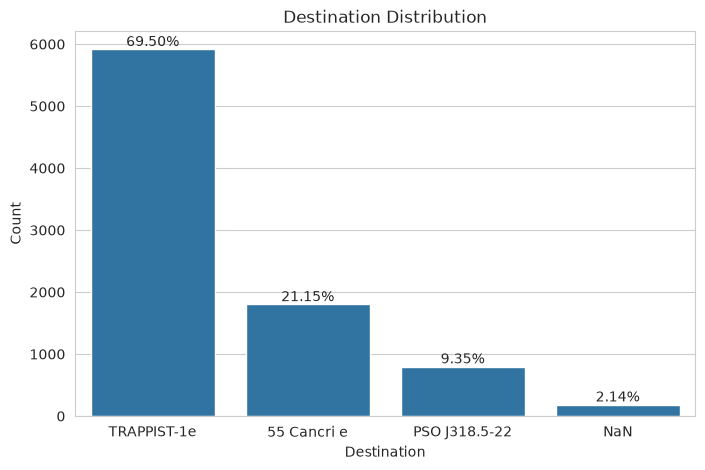

In [27]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Destination"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Destination"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Destination Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Destination")
plt.show()

##### Does Destination Affect Transported Status?

In [28]:
destination_crosstab = pd.crosstab(index=df["Transported"], columns=df["Destination"], margins=True)
destination_crosstab = destination_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
destination_crosstab

,55 Cancri e,PSO J318.5-22,TRAPPIST-1e,Total Cols
Not Transported,702,395,3128,4225
Transported,1098,401,2787,4286
Total Rows,1800,796,5915,8511


In [107]:
destination_prob = destination_crosstab / destination_crosstab.loc["Total Rows"]
destination_prob

,55 Cancri e,PSO J318.5-22,TRAPPIST-1e,Total Cols
Not Transported,0.39,0.496231,0.528825,0.496416
Transported,0.61,0.503769,0.471175,0.503584
Total Rows,1.00,1.000000,1.000000,1.000000


In [108]:
destination_prob = destination_prob.stack()["Transported"].drop("Total Cols")

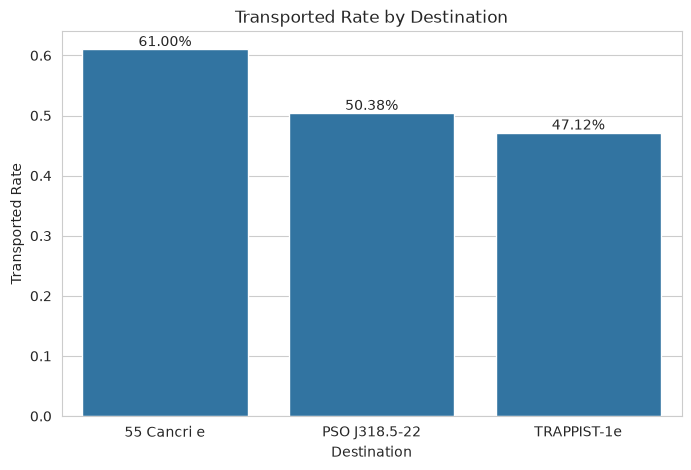

In [109]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(destination_prob)
ax.bar_label(ax.containers[0], labels=destination_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Destination")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Destination")
plt.show()

#### Age

In [30]:
df["Age"].describe()

count    8514.000000
mean       28.827930
std        14.489021
min         0.000000
25%        19.000000
50%        27.000000
75%        38.000000
max        79.000000
Name: Age, dtype: float64

In [31]:
df["Age"].isna().sum()

np.int64(179)

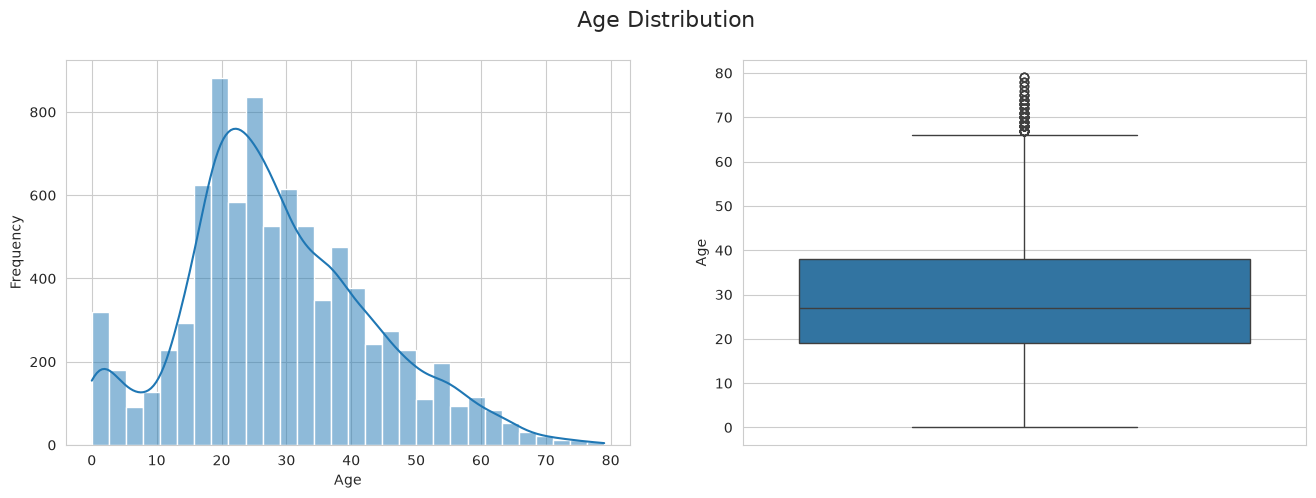

In [32]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Age Distribution", fontsize=16)

ax = sns.histplot(df["Age"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Age")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Age"], ax=axes[1])
ax.set_ylabel("Age")

plt.show()

##### Does Age Affect Transported Status?

In [166]:
age_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Age"], range(0, int(df["Age"].max()) + 10, 10), include_lowest=True), margins=True)
age_crosstab = age_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
age_crosstab

,"(-0.001, 10.0]","(10.0, 20.0]","(20.0, 30.0]","(30.0, 40.0]","(40.0, 50.0]","(50.0, 60.0]","(60.0, 70.0]","(70.0, 80.0]",Total Cols
Not Transported,210,828,1416,893,499,264,93,23,4226
Transported,508,889,1252,787,495,253,90,14,4288
Total Rows,718,1717,2668,1680,994,517,183,37,8514


In [167]:
age_prob = age_crosstab / age_crosstab.loc["Total Rows"]
age_prob

,"(-0.001, 10.0]","(10.0, 20.0]","(20.0, 30.0]","(30.0, 40.0]","(40.0, 50.0]","(50.0, 60.0]","(60.0, 70.0]","(70.0, 80.0]",Total Cols
Not Transported,0.292479,0.482236,0.530735,0.531548,0.502012,0.510638,0.508197,0.621622,0.496359
Transported,0.707521,0.517764,0.469265,0.468452,0.497988,0.489362,0.491803,0.378378,0.503641
Total Rows,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [168]:
age_prob = age_prob.stack()["Transported"].drop("Total Cols")
age_prob.index = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80"]

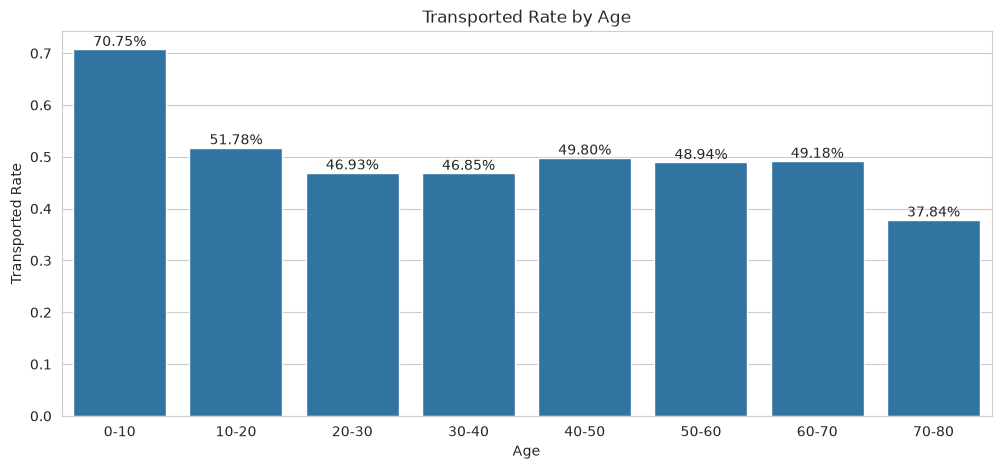

In [169]:
plt.figure(figsize=(12, 5))
ax = sns.barplot(age_prob)
ax.bar_label(ax.containers[0], age_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Age")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Age")
plt.show()

#### Cryo Sleep

In [35]:
df["Cryo_Sleep"].value_counts(dropna=False)

Cryo_Sleep
False    5439
True     3254
Name: count, dtype: int64

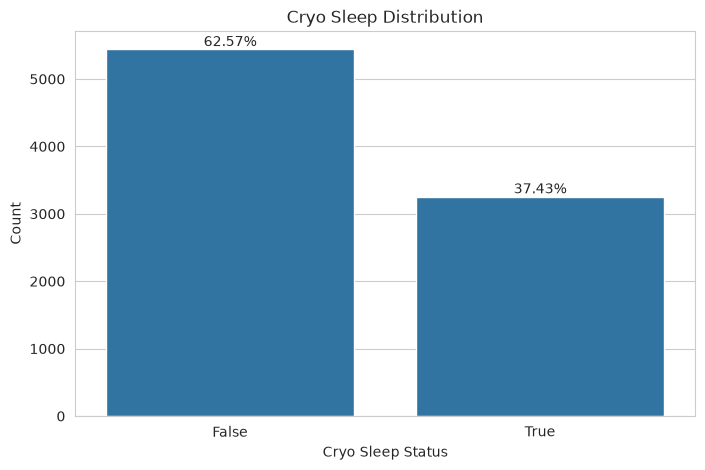

In [36]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cryo_Sleep"].value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cryo_Sleep"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cryo Sleep Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cryo Sleep Status")
plt.show()

##### Does Cryo Sleep Affect Transported Status?

In [37]:
cryo_sleep_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cryo_Sleep"], margins=True)
cryo_sleep_crosstab = cryo_sleep_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    }, 
    columns={
        False: "Not Sleep",
        True: "Sleep",
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cryo_sleep_crosstab

,Not Sleep,Sleep,Total Cols
Not Transported,3650,665,4315
Transported,1789,2589,4378
Total Rows,5439,3254,8693


In [115]:
cryo_sleep_prob = cryo_sleep_crosstab / cryo_sleep_crosstab.loc["Total Rows"]
cryo_sleep_prob

,Not Sleep,Sleep,Total Cols
Not Transported,0.671079,0.204364,0.496376
Transported,0.328921,0.795636,0.503624
Total Rows,1.000000,1.000000,1.000000


In [116]:
cryo_sleep_prob = cryo_sleep_prob.stack()["Transported"].drop("Total Cols")

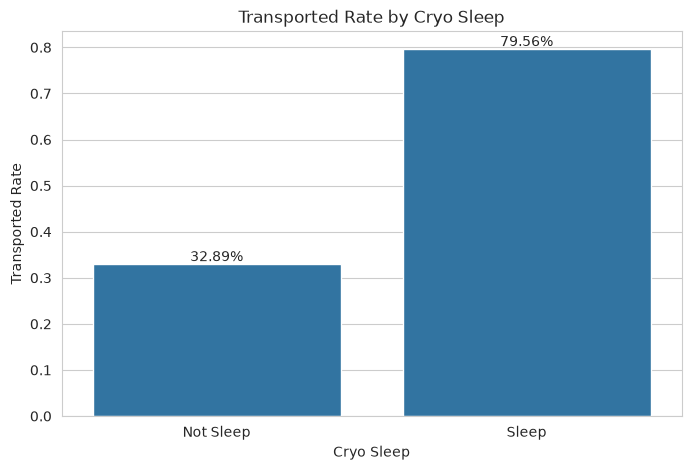

In [170]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cryo_sleep_prob)
ax.bar_label(ax.containers[0], labels=cryo_sleep_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cryo Sleep")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cryo Sleep")
plt.show()

#### VIP

In [39]:
df["VIP"].value_counts(dropna=False)

VIP
False    8291
True      402
Name: count, dtype: int64

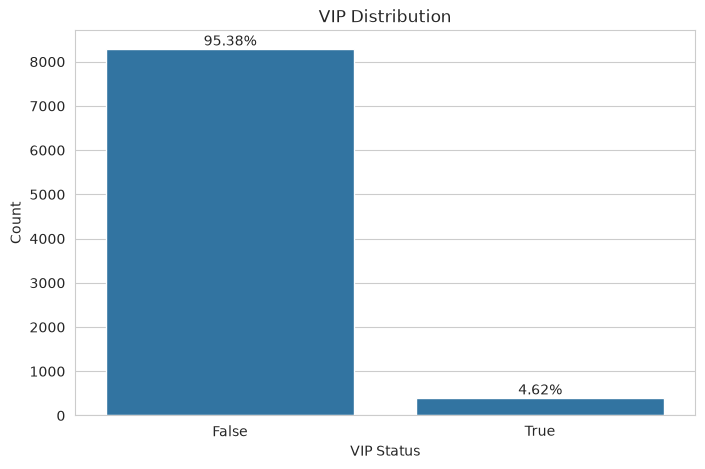

In [40]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["VIP"].value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["VIP"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("VIP Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("VIP Status")
plt.show()

##### Does VIP Status Affect Transported Status?

In [41]:
vip_crosstab = pd.crosstab(index=df["Transported"], columns=df["VIP"], margins=True)
vip_crosstab = vip_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    }, 
    columns={
        False: "Not VIP",
        True: "VIP",
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
vip_crosstab

,Not VIP,VIP,Total Cols
Not Transported,4093,222,4315
Transported,4198,180,4378
Total Rows,8291,402,8693


In [118]:
vip_prob = vip_crosstab / vip_crosstab.loc["Total Rows"]
vip_prob

,Not VIP,VIP,Total Cols
Not Transported,0.493668,0.552239,0.496376
Transported,0.506332,0.447761,0.503624
Total Rows,1.000000,1.000000,1.000000


In [119]:
vip_prob = vip_prob.stack()["Transported"].drop("Total Cols")

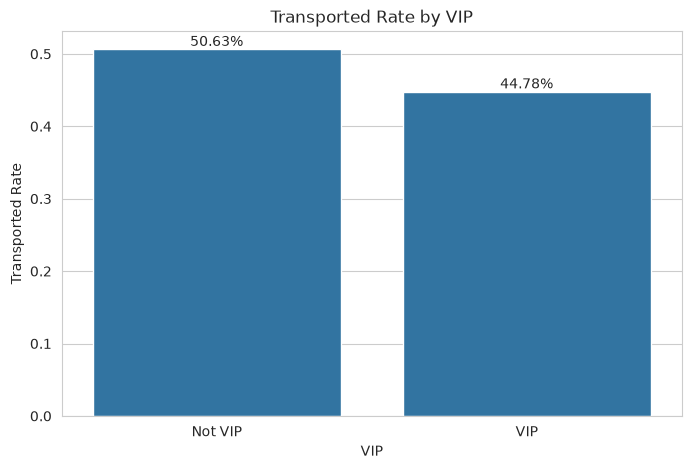

In [171]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(vip_prob)
ax.bar_label(ax.containers[0], labels=vip_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by VIP")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("VIP")
plt.show()

#### Room Service

In [43]:
df["Room_Service"].describe()

count     8512.000000
mean       224.687617
std        666.717663
min          0.000000
25%          0.000000
50%          0.000000
75%         47.000000
max      14327.000000
Name: Room_Service, dtype: float64

In [44]:
df["Room_Service"].isna().sum()

np.int64(181)

In [45]:
df["Room_Service"].value_counts(dropna=False)

Room_Service
0.0       5577
NaN        181
1.0        117
2.0         79
3.0         61
          ... 
459.0        1
1003.0       1
1569.0       1
8586.0       1
745.0        1
Name: count, Length: 1274, dtype: int64

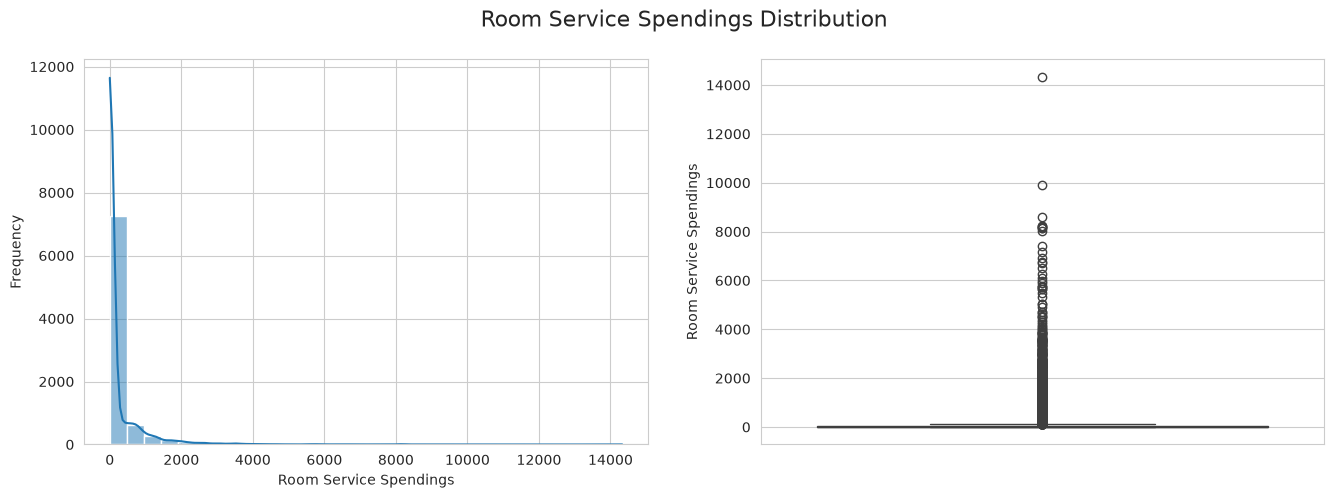

In [46]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Room Service Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Room_Service"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Room Service Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Room_Service"], ax=axes[1])
ax.set_ylabel("Room Service Spendings")

plt.show()

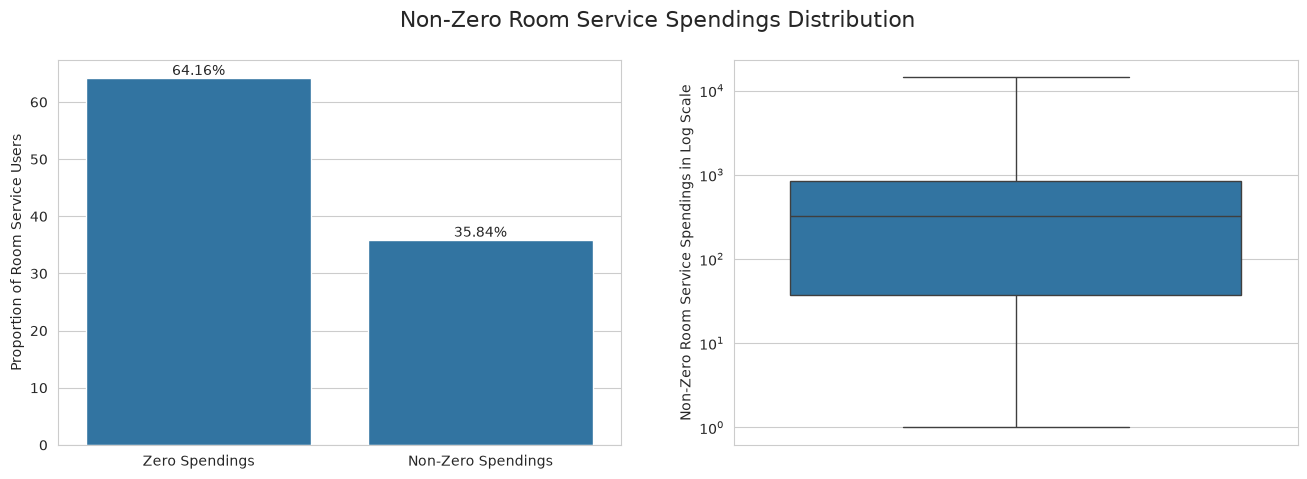

In [47]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Room Service Spendings Distribution", fontsize=16)

room_service_proportion = (df["Room_Service"] == 0).value_counts(normalize=True) * 100
room_service_proportion = room_service_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(room_service_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Room Service Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Room_Service > 0")["Room_Service"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Room Service Spendings in Log Scale")

plt.show()

#### Does Room Service Affect Transported Status?

In [154]:
room_service_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Room_Service"], [0, 0.1, df["Room_Service"].max()], include_lowest=True), margins=True)
room_service_crosstab = room_service_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
room_service_crosstab

,"(-0.001, 0.1]","(0.1, 14327.0]",Total Cols
Not Transported,2045,2172,4217
Transported,3532,763,4295
Total Rows,5577,2935,8512


In [155]:
room_service_prob = room_service_crosstab / room_service_crosstab.loc["Total Rows"]
room_service_prob

,"(-0.001, 0.1]","(0.1, 14327.0]",Total Cols
Not Transported,0.366685,0.740034,0.495418
Transported,0.633315,0.259966,0.504582
Total Rows,1.000000,1.000000,1.000000


In [156]:
room_service_prob = room_service_prob.stack()["Transported"].drop("Total Cols")
room_service_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

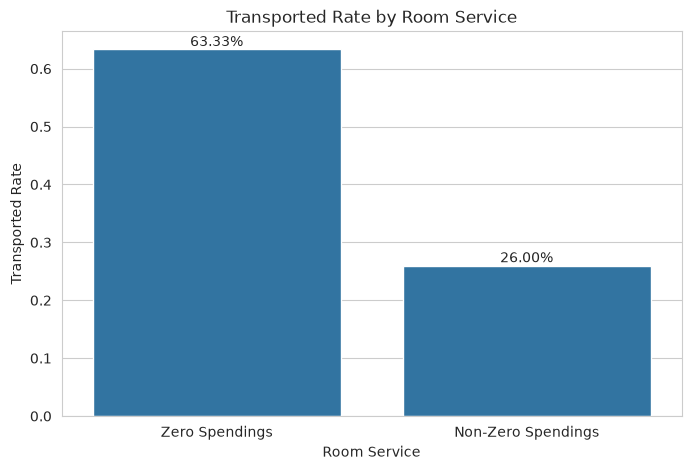

In [172]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(room_service_prob)
ax.bar_label(ax.containers[0], labels=room_service_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Room Service")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Room Service")
plt.show()

#### Food Court

In [50]:
df["Food_Court"].describe()

count     8510.000000
mean       458.077203
std       1611.489240
min          0.000000
25%          0.000000
50%          0.000000
75%         76.000000
max      29813.000000
Name: Food_Court, dtype: float64

In [51]:
df["Food_Court"].isna().sum()

np.int64(183)

In [52]:
df["Food_Court"].value_counts(dropna=False)

Food_Court
0.0       5456
NaN        183
1.0        116
2.0         75
3.0         53
          ... 
1015.0       1
1146.0       1
3208.0       1
6819.0       1
4688.0       1
Name: count, Length: 1508, dtype: int64

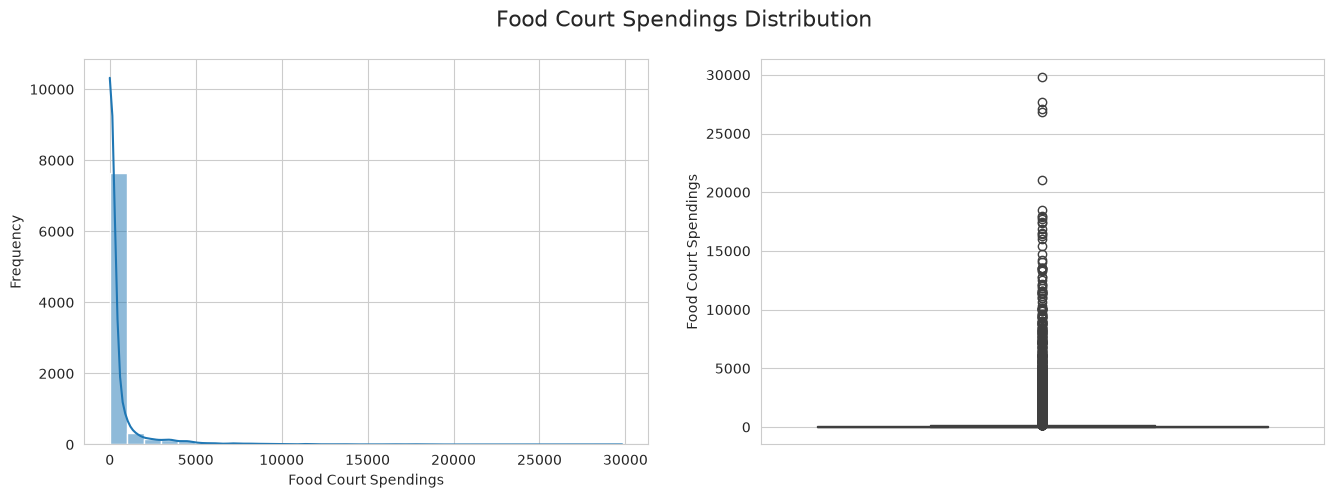

In [53]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Food Court Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Food_Court"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Food Court Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Food_Court"], ax=axes[1])
ax.set_ylabel("Food Court Spendings")

plt.show()

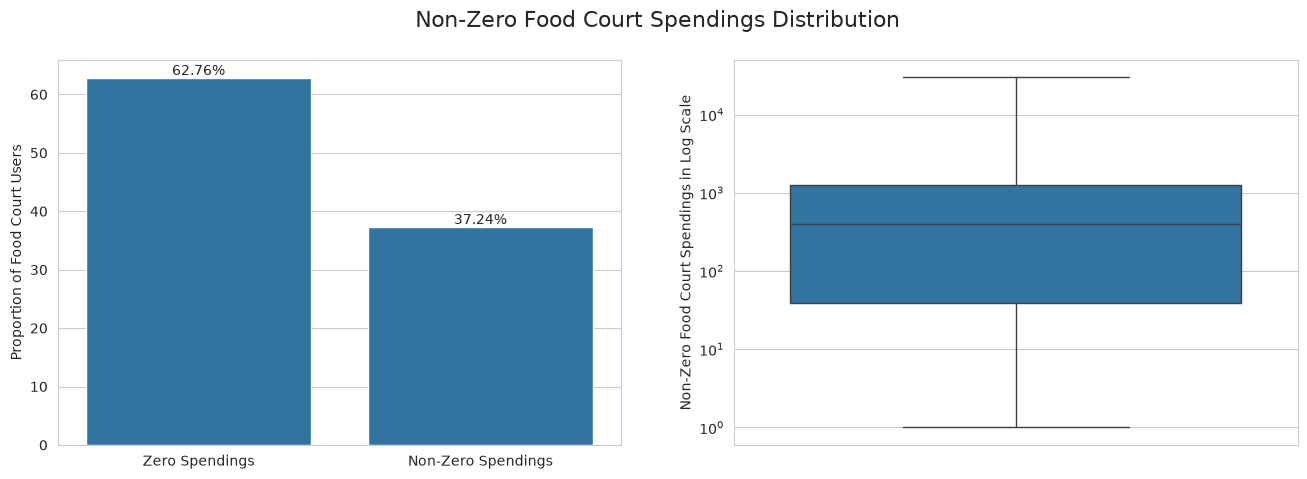

In [54]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Food Court Spendings Distribution", fontsize=16)

food_court_proportion = (df["Food_Court"] == 0).value_counts(normalize=True) * 100
food_court_proportion = food_court_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(food_court_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Food Court Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Food_Court > 0")["Food_Court"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Food Court Spendings in Log Scale")

plt.show()

#### Does Food Court Affect Transported Status?

In [55]:
food_court_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Food_Court"], [0, 0.1, df["Food_Court"].max()], include_lowest=True), margins=True)
food_court_crosstab = food_court_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
food_court_crosstab

,"(-0.001, 0.1]","(0.1, 29813.0]",Total Cols
Not Transported,2232,1999,4231
Transported,3224,1055,4279
Total Rows,5456,3054,8510


In [158]:
food_court_prob = food_court_crosstab / food_court_crosstab.loc["Total Rows"]
food_court_prob

,"(-0.001, 0.1]","(0.1, 29813.0]",Total Cols
Not Transported,0.409091,0.654551,0.49718
Transported,0.590909,0.345449,0.50282
Total Rows,1.000000,1.000000,1.00000


In [159]:
food_court_prob = food_court_prob.stack()["Transported"].drop("Total Cols")
food_court_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

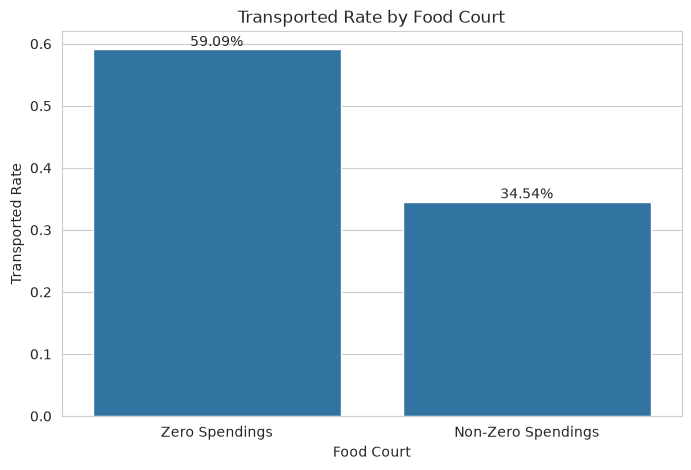

In [173]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(food_court_prob)
ax.bar_label(ax.containers[0], labels=food_court_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Food Court")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Food Court")
plt.show()

#### Shopping Mall

In [57]:
df["Shopping_Mall"].describe()

count     8485.000000
mean       173.729169
std        604.696458
min          0.000000
25%          0.000000
50%          0.000000
75%         27.000000
max      23492.000000
Name: Shopping_Mall, dtype: float64

In [58]:
df["Shopping_Mall"].isna().sum()

np.int64(208)

In [59]:
df["Shopping_Mall"].value_counts(dropna=False)

Shopping_Mall
0.0       5587
NaN        208
1.0        153
2.0         80
3.0         59
          ... 
918.0        1
205.0        1
1085.0       1
510.0        1
1872.0       1
Name: count, Length: 1116, dtype: int64

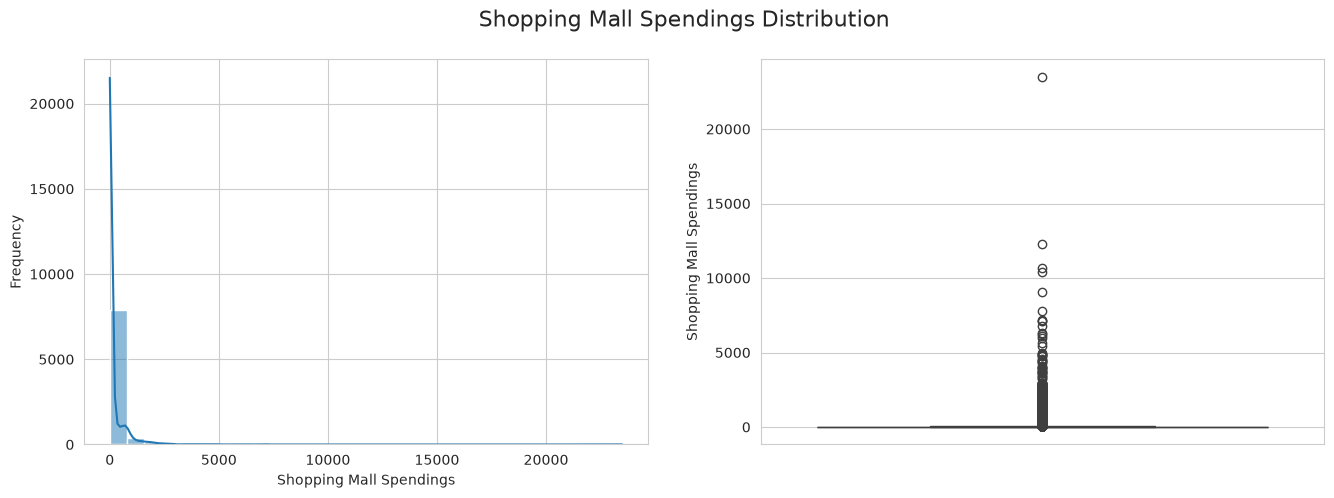

In [60]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Shopping Mall Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Shopping_Mall"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Shopping Mall Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Shopping_Mall"], ax=axes[1])
ax.set_ylabel("Shopping Mall Spendings")

plt.show()

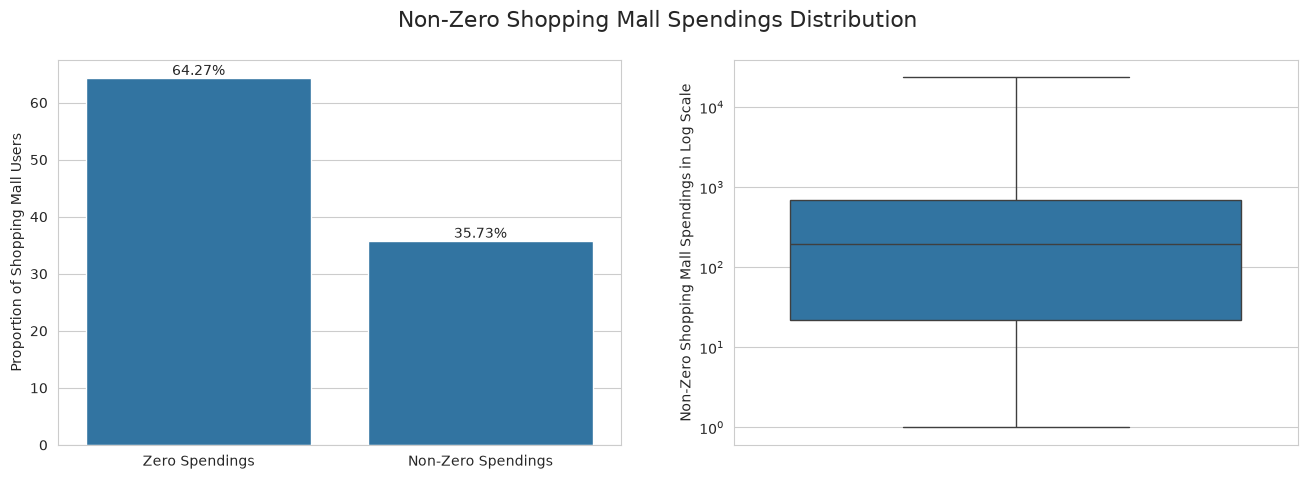

In [61]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Shopping Mall Spendings Distribution", fontsize=16)

shopping_mall_proportion = (df["Shopping_Mall"] == 0).value_counts(normalize=True) * 100
shopping_mall_proportion = shopping_mall_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(shopping_mall_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Shopping Mall Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Shopping_Mall > 0")["Shopping_Mall"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Shopping Mall Spendings in Log Scale")

plt.show()

#### Does Shopping Mall Affect Transported Status?

In [62]:
shopping_mall_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Shopping_Mall"], [0, 0.1, df["Shopping_Mall"].max()], include_lowest=True), margins=True)
shopping_mall_crosstab = shopping_mall_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
shopping_mall_crosstab

,"(-0.001, 0.1]","(0.1, 23492.0]",Total Cols
Not Transported,2242,1979,4221
Transported,3345,919,4264
Total Rows,5587,2898,8485


In [174]:
shopping_mall_prob = shopping_mall_crosstab / shopping_mall_crosstab.loc["Total Rows"]
shopping_mall_prob

,"(-0.001, 0.1]","(0.1, 23492.0]",Total Cols
Not Transported,0.401289,0.682885,0.497466
Transported,0.598711,0.317115,0.502534
Total Rows,1.000000,1.000000,1.000000


In [175]:
shopping_mall_prob = shopping_mall_prob.stack()["Transported"].drop("Total Cols")
shopping_mall_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

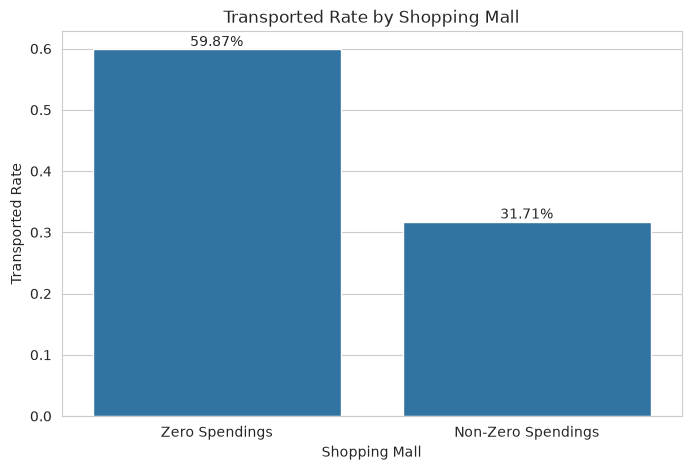

In [176]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(shopping_mall_prob)
ax.bar_label(ax.containers[0], labels=shopping_mall_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Shopping Mall")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Shopping Mall")
plt.show()

#### Spa

In [64]:
df["Spa"].describe()

count     8510.000000
mean       311.138778
std       1136.705535
min          0.000000
25%          0.000000
50%          0.000000
75%         59.000000
max      22408.000000
Name: Spa, dtype: float64

In [65]:
df["Spa"].isna().sum()

np.int64(183)

In [66]:
df["Spa"].value_counts(dropna=False)

Spa
0.0       5324
NaN        183
1.0        146
2.0        105
3.0         53
          ... 
269.0        1
3238.0       1
2868.0       1
1107.0       1
1643.0       1
Name: count, Length: 1328, dtype: int64

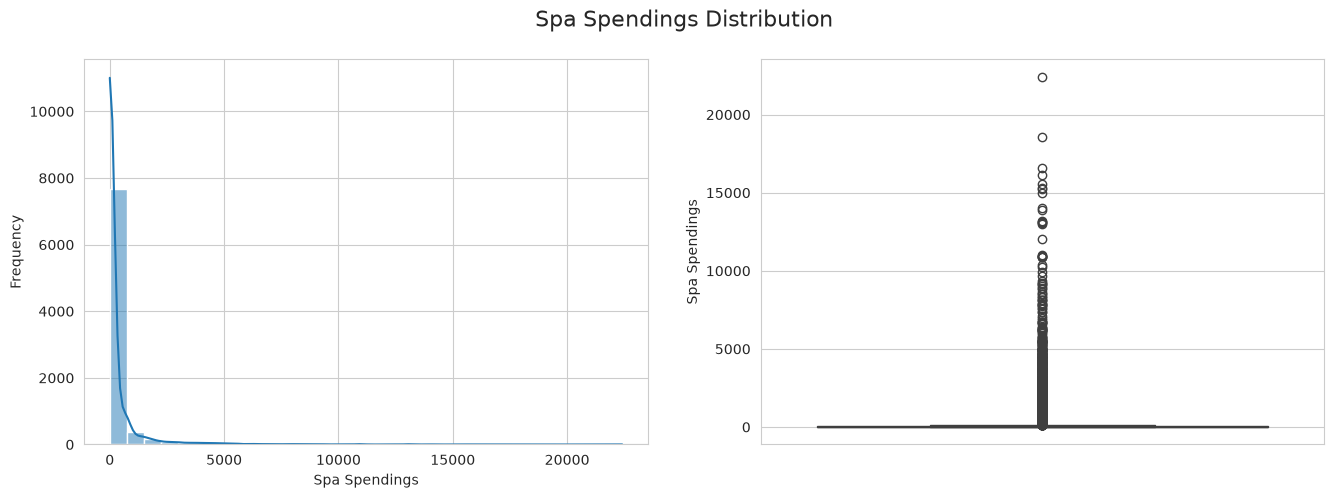

In [67]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("Spa Spendings Distribution", fontsize=16)

ax = sns.histplot(df["Spa"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("Spa Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["Spa"], ax=axes[1])
ax.set_ylabel("Spa Spendings")

plt.show()

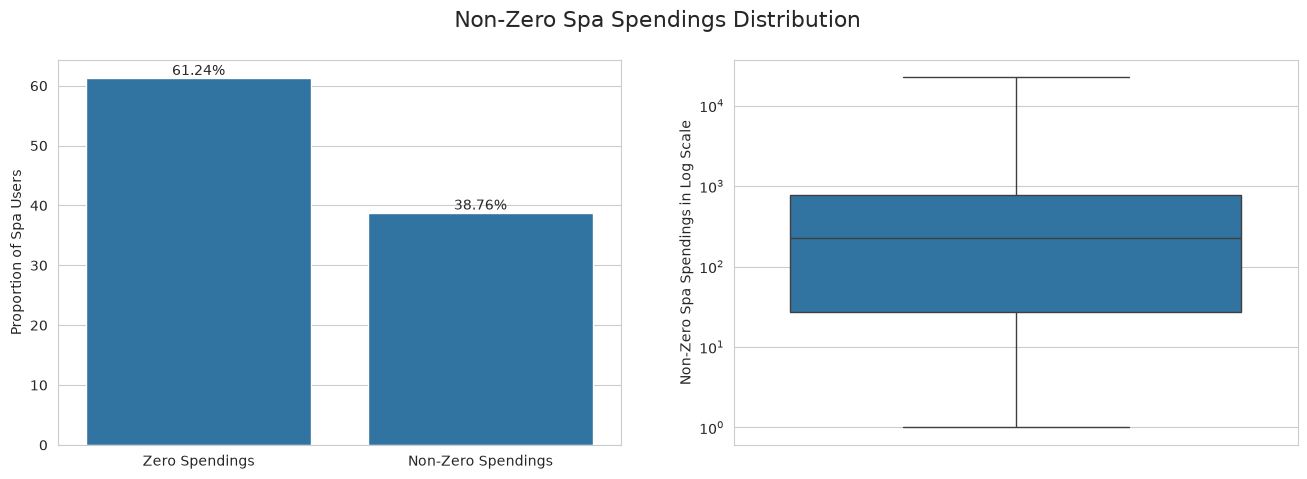

In [68]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero Spa Spendings Distribution", fontsize=16)

spa_proportion = (df["Spa"] == 0).value_counts(normalize=True) * 100
spa_proportion = spa_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(spa_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of Spa Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("Spa > 0")["Spa"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero Spa Spendings in Log Scale")

plt.show()

#### Does Spa Affect Transported Status?

In [69]:
spa_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["Spa"], [0, 0.1, df["Spa"].max()], include_lowest=True), margins=True)
spa_crosstab = spa_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
spa_crosstab

,"(-0.001, 0.1]","(0.1, 22408.0]",Total Cols
Not Transported,1921,2302,4223
Transported,3403,884,4287
Total Rows,5324,3186,8510


In [178]:
spa_prob = spa_crosstab / spa_crosstab.loc["Total Rows"]
spa_prob

,"(-0.001, 0.1]","(0.1, 22408.0]",Total Cols
Not Transported,0.360819,0.722536,0.49624
Transported,0.639181,0.277464,0.50376
Total Rows,1.000000,1.000000,1.00000


In [179]:
spa_prob = spa_prob.stack()["Transported"].drop("Total Cols")
spa_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

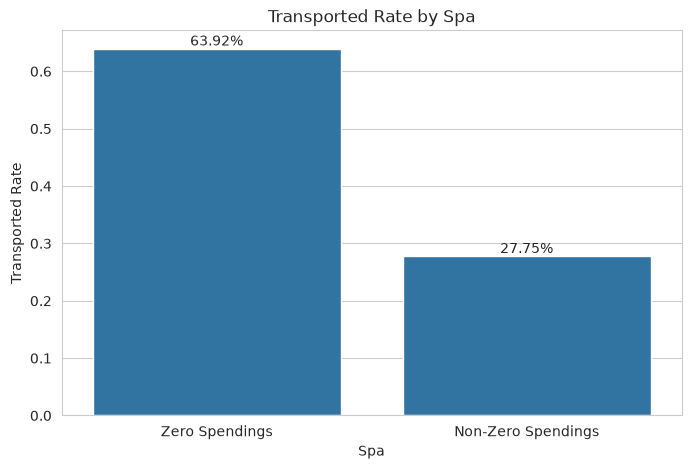

In [180]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(spa_prob)
ax.bar_label(ax.containers[0], labels=spa_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Spa")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Spa")
plt.show()

#### VR Deck

In [71]:
df["VR_Deck"].describe()

count     8505.000000
mean       304.854791
std       1145.717189
min          0.000000
25%          0.000000
50%          0.000000
75%         46.000000
max      24133.000000
Name: VR_Deck, dtype: float64

In [72]:
df["VR_Deck"].isna().sum()

np.int64(188)

In [73]:
df["VR_Deck"].value_counts(dropna=False)

VR_Deck
0.0       5495
NaN        188
1.0        139
2.0         70
3.0         56
          ... 
5839.0       1
2252.0       1
1164.0       1
971.0        1
3235.0       1
Name: count, Length: 1307, dtype: int64

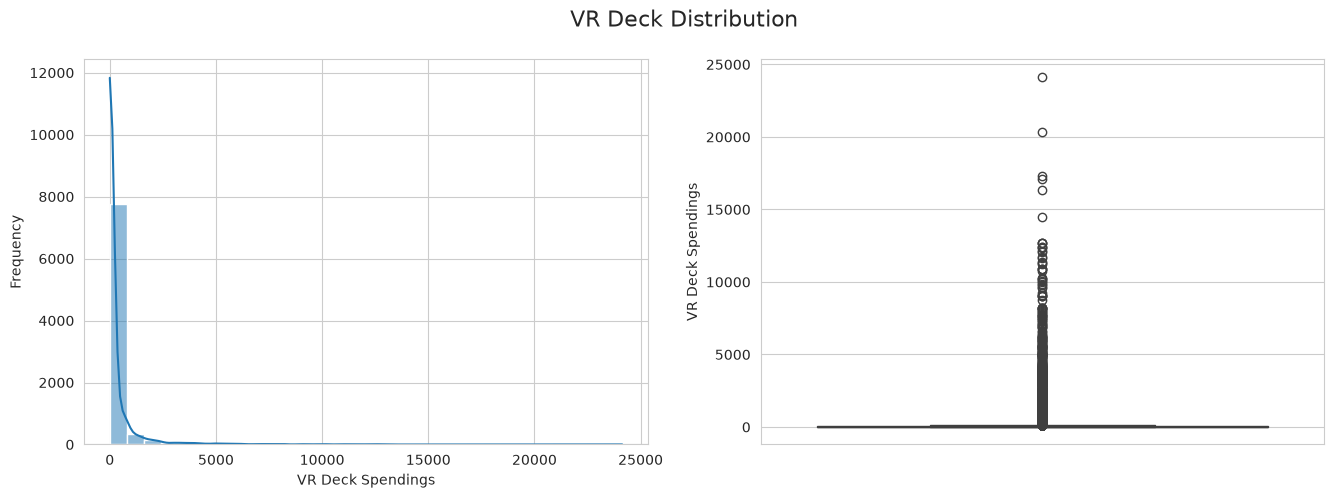

In [74]:
fig, axes = plt.subplots(ncols=2, figsize=(16,5))
fig.suptitle("VR Deck Distribution", fontsize=16)

ax = sns.histplot(df["VR_Deck"], ax=axes[0], bins=30, kde=True)
ax.set_xlabel("VR Deck Spendings")
ax.set_ylabel("Frequency")

ax = sns.boxplot(df["VR_Deck"], ax=axes[1])
ax.set_ylabel("VR Deck Spendings")

plt.show()

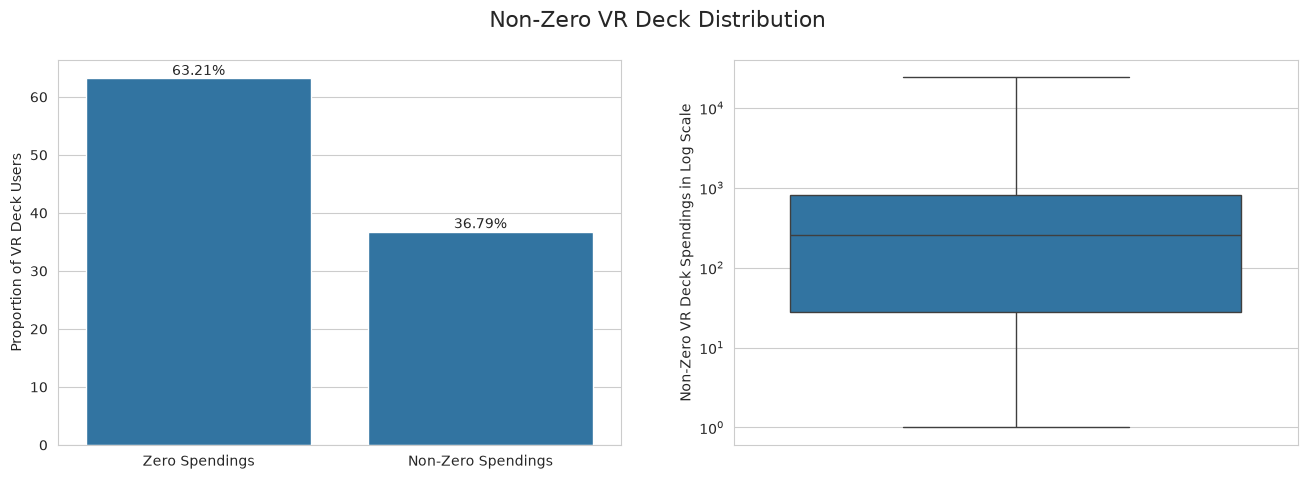

In [75]:
fig, axes = plt.subplots(ncols=2, figsize=(16, 5))
fig.suptitle("Non-Zero VR Deck Distribution", fontsize=16)

vr_deck_proportion = (df["VR_Deck"] == 0).value_counts(normalize=True) * 100
vr_deck_proportion = vr_deck_proportion.rename(index={False: "Non-Zero Spendings", True: "Zero Spendings"})

ax = sns.barplot(vr_deck_proportion, ax=axes[0])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylabel("Proportion of VR Deck Users")
ax.set_xlabel("")

ax = sns.boxplot(df.query("VR_Deck > 0")["VR_Deck"], ax=axes[1], log_scale=True)
ax.set_ylabel("Non-Zero VR Deck Spendings in Log Scale")

plt.show()

#### Does VR Deck Affect Transported Status?

In [76]:
vr_deck_crosstab = pd.crosstab(index=df["Transported"], columns=pd.cut(df["VR_Deck"], [0, 0.1, df["VR_Deck"].max()], include_lowest=True), margins=True)
vr_deck_crosstab = vr_deck_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
vr_deck_crosstab

,"(-0.001, 0.1]","(0.1, 24133.0]",Total Cols
Not Transported,2044,2181,4225
Transported,3451,829,4280
Total Rows,5495,3010,8505


In [181]:
vr_deck_prob = vr_deck_crosstab / vr_deck_crosstab.loc["Total Rows"]
vr_deck_prob

,"(-0.001, 0.1]","(0.1, 24133.0]",Total Cols
Not Transported,0.371975,0.724585,0.496767
Transported,0.628025,0.275415,0.503233
Total Rows,1.000000,1.000000,1.000000


In [182]:
vr_deck_prob = vr_deck_prob.stack()["Transported"].drop("Total Cols")
vr_deck_prob.index = ["Zero Spendings", "Non-Zero Spendings"]

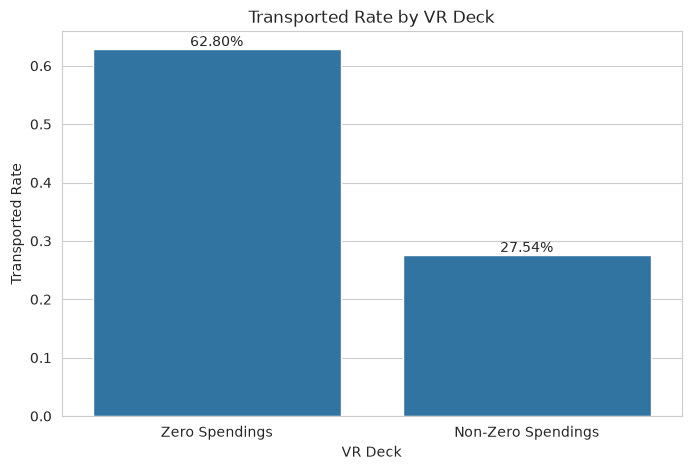

In [183]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(vr_deck_prob)
ax.bar_label(ax.containers[0], labels=vr_deck_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by VR Deck")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("VR Deck")
plt.show()

#### Cabin Deck

In [78]:
df["Cabin_Deck"].value_counts(dropna=False)

Cabin_Deck
F      2794
G      2559
E       876
B       779
C       747
D       478
A       256
NaN     199
T         5
Name: count, dtype: int64

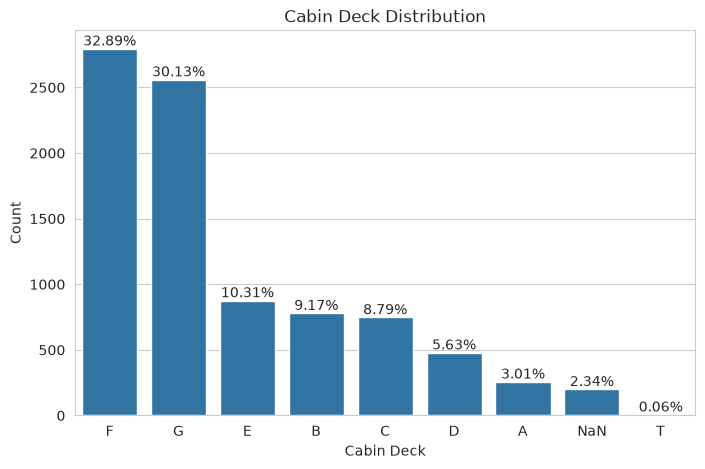

In [79]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cabin_Deck"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cabin_Deck"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cabin Deck Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cabin Deck")
plt.show()

##### Does Cabin Deck Affect Transported Status?

In [80]:
cabin_deck_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cabin_Deck"], margins=True)
cabin_deck_crosstab = cabin_deck_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_deck_crosstab

,A,B,C,D,E,F,G,T,Total Cols
Not Transported,129,207,239,271,563,1565,1238,4,4216
Transported,127,572,508,207,313,1229,1321,1,4278
Total Rows,256,779,747,478,876,2794,2559,5,8494


In [186]:
cabin_deck_prob = cabin_deck_crosstab / cabin_deck_crosstab.loc["Total Rows"]
cabin_deck_prob

,A,B,C,D,E,F,G,T,Total Cols
Not Transported,0.503906,0.265725,0.319946,0.566946,0.642694,0.560129,0.483783,0.8,0.49635
Transported,0.496094,0.734275,0.680054,0.433054,0.357306,0.439871,0.516217,0.2,0.50365
Total Rows,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.00000


In [187]:
cabin_deck_prob = cabin_deck_prob.stack()["Transported"].drop("Total Cols")

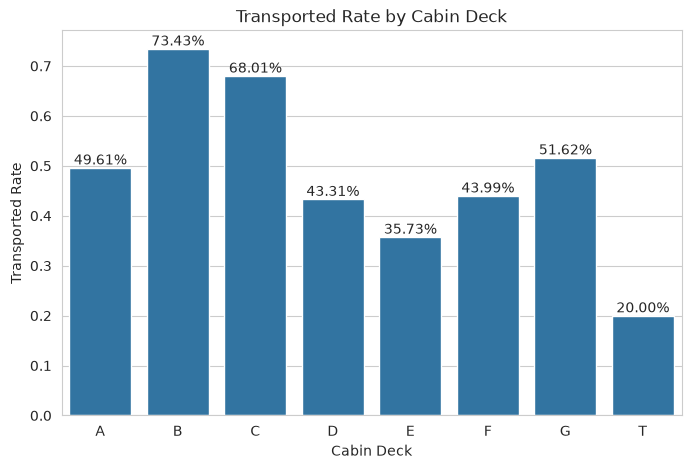

In [188]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cabin_deck_prob)
ax.bar_label(ax.containers[0], labels=cabin_deck_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Deck")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Deck")
plt.show()

#### Cabin Side

In [82]:
df["Cabin_Side"].value_counts(dropna=False)

Cabin_Side
S      4288
P      4206
NaN     199
Name: count, dtype: int64

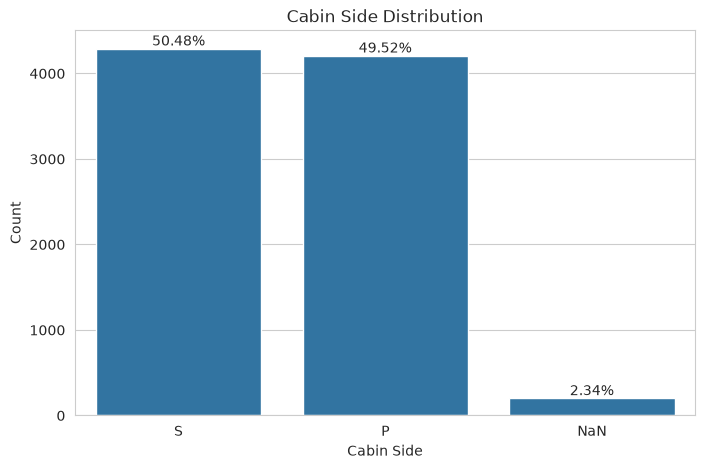

In [83]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cabin_Side"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cabin_Side"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cabin Side Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cabin Side")
plt.show()

##### Does Cabin Side Affect Transported Status?

In [84]:
cabin_side_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cabin_Side"], margins=True)
cabin_side_crosstab = cabin_side_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_side_crosstab

,P,S,Total Cols
Not Transported,2308,1908,4216
Transported,1898,2380,4278
Total Rows,4206,4288,8494


In [100]:
cabin_side_prob = cabin_side_crosstab / cabin_side_crosstab.loc["Total Rows"]
cabin_side_prob

,P,S,Total Cols
Not Transported,0.54874,0.444963,0.49635
Transported,0.45126,0.555037,0.50365
Total Rows,1.00000,1.000000,1.00000


In [101]:
cabin_side_prob = cabin_side_prob.stack()["Transported"].drop("Total Cols")

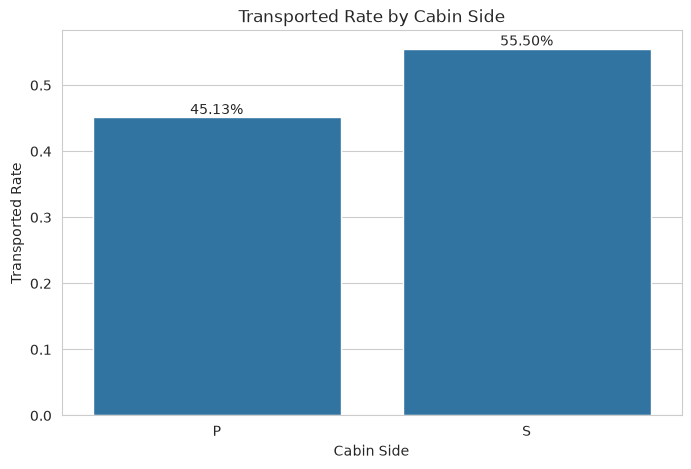

In [102]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cabin_side_prob)
ax.bar_label(ax.containers[0], labels=cabin_side_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Side")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Side")
plt.show()

#### Cabin Group Size

In [86]:
df["Cabin_Group_Size"].value_counts(dropna=False)

Cabin_Group_Size
 1.0    5427
 2.0    1372
 3.0     747
 4.0     416
 5.0     235
NaN      199
 6.0     198
 7.0      91
 8.0       8
Name: count, dtype: int64

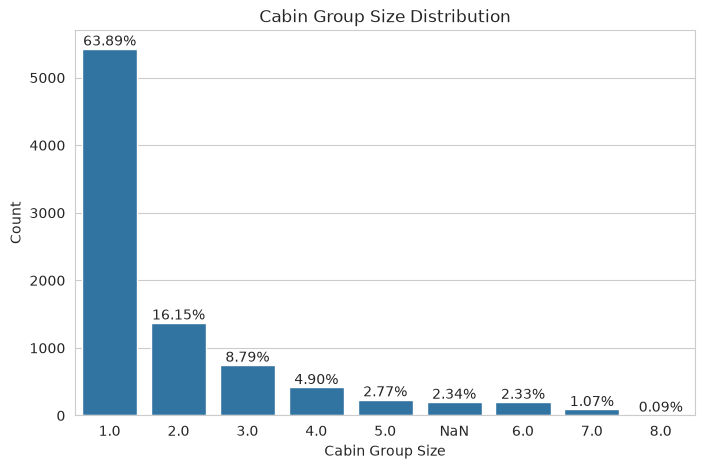

In [87]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Cabin_Group_Size"].astype("object").fillna("NaN").value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Cabin_Group_Size"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Cabin Group Size Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Cabin Group Size")
plt.show()

##### Does Cabin Group Size Affect Transported Status?

In [88]:
cabin_group_size_crosstab = pd.crosstab(index=df["Transported"], columns=df["Cabin_Group_Size"], margins=True)
cabin_group_size_crosstab = cabin_group_size_crosstab.rename(
    index={
        False: "Not Transported",
        True: "Transported",
        "All": "Total Rows",
    },
    columns={
        "All": "Total Cols",
    }
).rename_axis(index=None, columns=None)
cabin_group_size_crosstab

,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,Total Cols
Not Transported,3009,555,290,152,93,73,39,5,4216
Transported,2418,817,457,264,142,125,52,3,4278
Total Rows,5427,1372,747,416,235,198,91,8,8494


In [89]:
cabin_group_size_prob = cabin_group_size_crosstab / cabin_group_size_crosstab.loc["Total Rows"]
cabin_group_size_prob

,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,Total Cols
Not Transported,0.55445,0.404519,0.38822,0.365385,0.395745,0.368687,0.428571,0.625,0.49635
Transported,0.44555,0.595481,0.61178,0.634615,0.604255,0.631313,0.571429,0.375,0.50365
Total Rows,1.00000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000,1.00000


In [90]:
cabin_group_size_prob = cabin_group_size_prob.stack()["Transported"].drop("Total Cols")

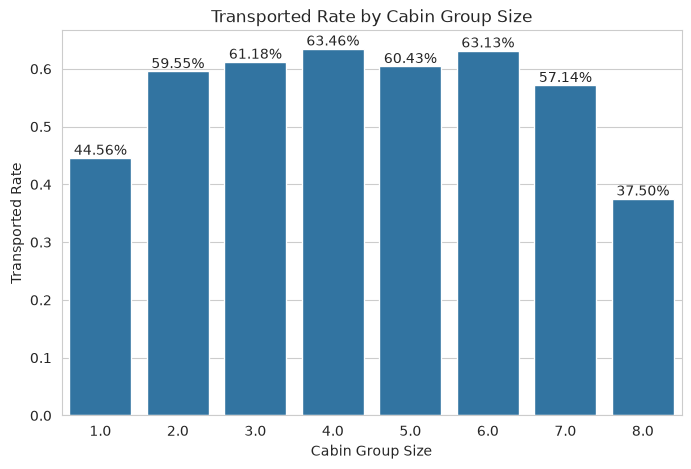

In [98]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(cabin_group_size_prob)
ax.bar_label(ax.containers[0], labels=cabin_group_size_prob.map(lambda x: f"{x * 100:.2f}%"))
ax.set_title("Transported Rate by Cabin Group Size")
ax.set_ylabel("Transported Rate")
ax.set_xlabel("Cabin Group Size")
plt.show()

#### Transported

In [93]:
df["Transported"].value_counts(dropna=False)

Transported
True     4378
False    4315
Name: count, dtype: int64

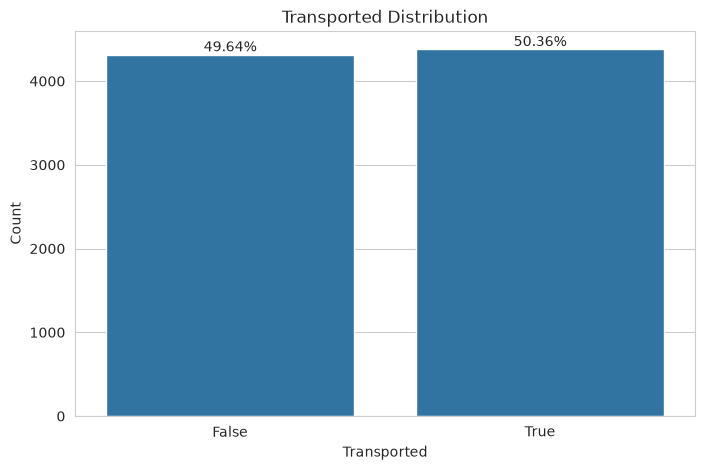

In [94]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(df["Transported"].value_counts())
ax.bar_label(ax.containers[0], labels=[f"{bar.get_height() / df["Transported"].count() * 100:.2f}%" for bar in ax.containers[0]])
ax.set_title("Transported Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Transported")
plt.show()

### Multivariate Analysis

In [95]:
# sns.pairplot(df, vars=["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"], hue="Transported")
# plt.show()

In [96]:
# sns.heatmap(df[["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"]].dropna().corr(), annot=True)
# plt.show()